In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load data
df = pd.read_csv("../data/AmesHousing.csv", sep='\t')

# Basic dimensions & first glance
print(df.shape)
df.head()

(2930, 82)


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [7]:
# Updated list with exact CSV column names
cols_na_means_none = [
    'Alley', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 
    'BsmtFin Type 1', 'BsmtFin Type 2', 'Fireplace Qu', 
    'Garage Type', 'Garage Finish', 'Garage Qual', 
    'Garage Cond', 'Pool QC', 'Fence', 'Misc Feature'
]

# Replace NaN with 'None' for these specific columns
df[cols_na_means_none] = df[cols_na_means_none].fillna('None')

In [25]:
# Identify numerical and categorical columns
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(include=['object', 'string']).columns.tolist()

print(f"Numerical columns: {len(num_cols)}")
print(f"Categorical columns: {len(cat_cols)}")

# Explicitly display summary statistics
display(df.describe().round(2))

# Check missing values
missing = df.isnull().sum()
missing_sorted = missing[missing > 0].sort_values(ascending=False)
display(missing_sorted)

print(f"Dataset Timespan: {df['Yr Sold'].min()}, {df['Yr Sold'].max()}")


Numerical columns: 39
Categorical columns: 43


,Order,PID,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
count,2930.00,2.930000e+03,2930.00,2440.00,2930.00,2930.00,2930.00,2930.00,2930.00,2907.00,...,2930.00,2930.00,2930.00,2930.00,2930.00,2930.00,2930.00,2930.00,2930.00,2930.00
mean,1465.50,7.144645e+08,57.39,69.22,10147.92,6.09,5.56,1971.36,1984.27,101.90,...,93.75,47.53,23.01,2.59,16.00,2.24,50.64,6.22,2007.79,180796.06
std,845.96,1.887308e+08,42.64,23.37,7880.02,1.41,1.11,30.25,20.86,179.11,...,126.36,67.48,64.14,25.14,56.09,35.60,566.34,2.71,1.32,79886.69
min,1.00,5.263011e+08,20.00,21.00,1300.00,1.00,1.00,1872.00,1950.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,2006.00,12789.00
25%,733.25,5.284770e+08,20.00,58.00,7440.25,5.00,5.00,1954.00,1965.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,4.00,2007.00,129500.00
50%,1465.50,5.354536e+08,50.00,68.00,9436.50,6.00,5.00,1973.00,1993.00,0.00,...,0.00,27.00,0.00,0.00,0.00,0.00,0.00,6.00,2008.00,160000.00
75%,2197.75,9.071811e+08,70.00,80.00,11555.25,7.00,6.00,2001.00,2004.00,164.00,...,168.00,70.00,0.00,0.00,0.00,0.00,0.00,8.00,2009.00,213500.00
max,2930.00,1.007100e+09,190.00,313.00,215245.00,10.00,9.00,2010.00,2010.00,1600.00,...,1424.00,742.00,1012.00,508.00,576.00,800.00,17000.00,12.00,2010.00,755000.00


Mas Vnr Type      1775
Lot Frontage       490
Garage Yr Blt      159
Mas Vnr Area        23
Bsmt Full Bath       2
Bsmt Half Bath       2
BsmtFin SF 1         1
BsmtFin SF 2         1
Bsmt Unf SF          1
Electrical           1
Total Bsmt SF        1
Garage Cars          1
Garage Area          1
dtype: int64

Dataset Timespan: 2006, 2010


In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

## 1. Cum sunt distribuite vanzarile in Ames?

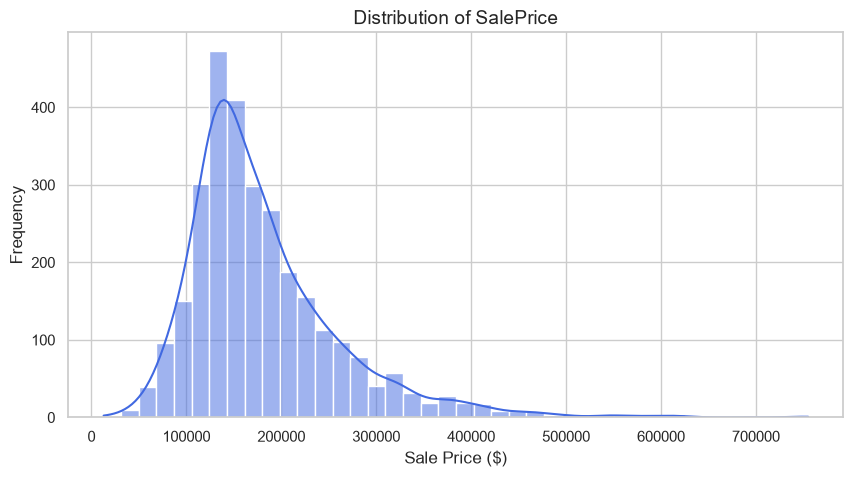

Skewness: 1.74


In [10]:
plt.figure(figsize=(10, 5))
sns.histplot(df['SalePrice'], kde=True, color='royalblue', bins=40)
plt.title('Distribution of SalePrice', fontsize=14)
plt.xlabel('Sale Price ($)')
plt.ylabel('Frequency')
plt.show()

print(f"Skewness: {df['SalePrice'].skew():.2f}")

## 2. Care atribute au cea mai mare corelatie liniara cu pretul?

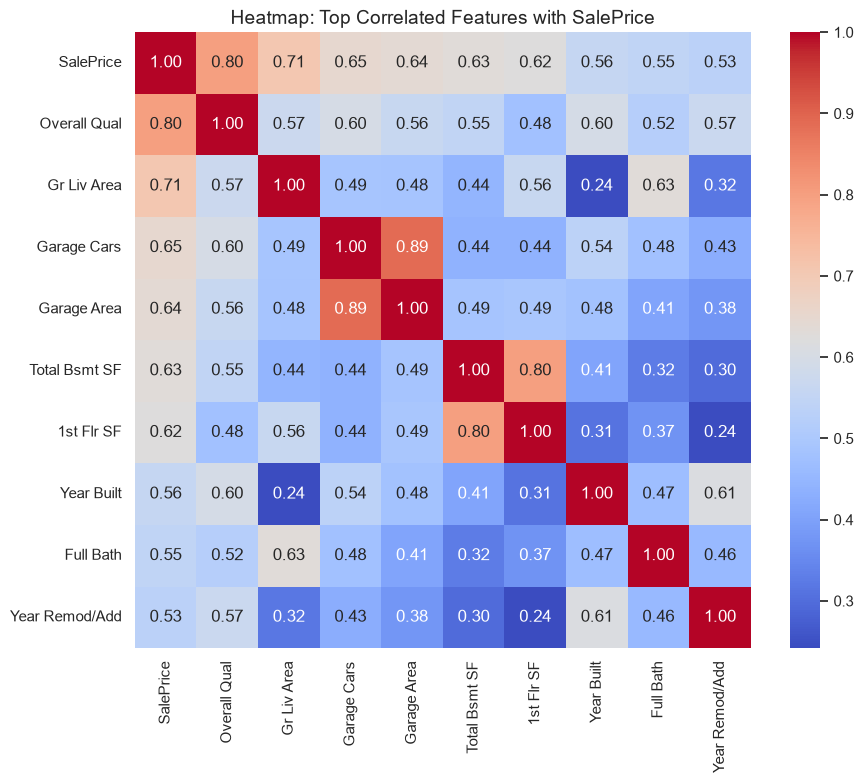

In [11]:
plt.figure(figsize=(10, 8))
# Select the top 10 numerical features most correlated with SalePrice
top_corr_features = df[num_cols].corr()['SalePrice'].abs().sort_values(ascending=False).head(10).index
corr_matrix = df[top_corr_features].corr()

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', cbar=True, square=True)
plt.title('Heatmap: Top Correlated Features with SalePrice', fontsize=14)
plt.show()

## 3. Pretul creste liniar cu aria proprietatii?

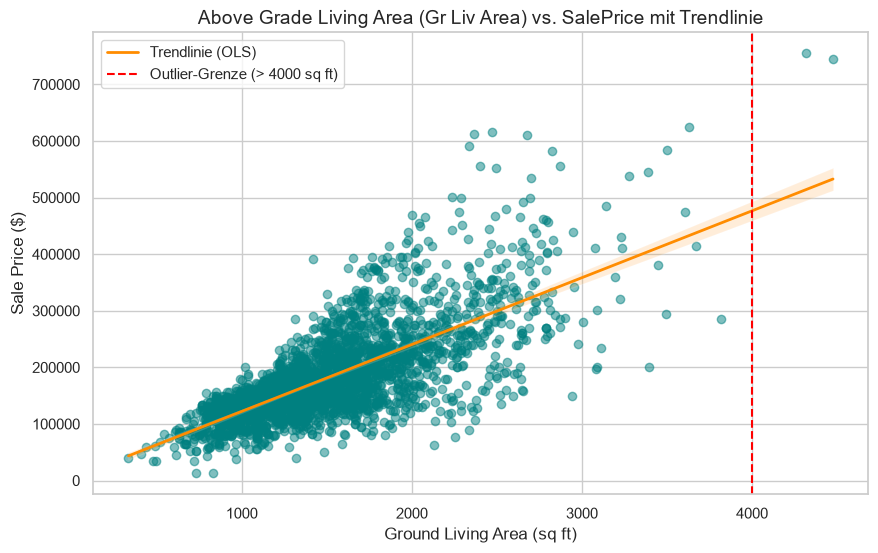

In [20]:
plt.figure(figsize=(10, 6))
df_cleaned = df.drop(df[(df['Gr Liv Area'] > 4000) & ((df['SalePrice'] < 300000))].index)

# Zeichnet den Scatter-Plot inklusive linearer Regressionslinie
sns.regplot(
    data=df_cleaned, 
    x='Gr Liv Area', 
    y='SalePrice', 
    scatter_kws={'alpha': 0.5, 'color': 'teal'}, 
    line_kws={'color': 'darkorange', 'linewidth': 2, 'label': 'Trendlinie (OLS)'}
)

# Schwellenwert-Linie für die bekannten Ames-Ausreißer (> 4000 sq ft)
plt.axvline(4000, color='red', linestyle='--', label='Outlier-Grenze (> 4000 sq ft)')

plt.title('Above Grade Living Area (Gr Liv Area) vs. SalePrice mit Trendlinie', fontsize=14)
plt.xlabel('Ground Living Area (sq ft)')
plt.ylabel('Sale Price ($)')
plt.legend()
plt.show()

## 4. Cum afecteaza scorul de calitate mediana si variatia pretului?

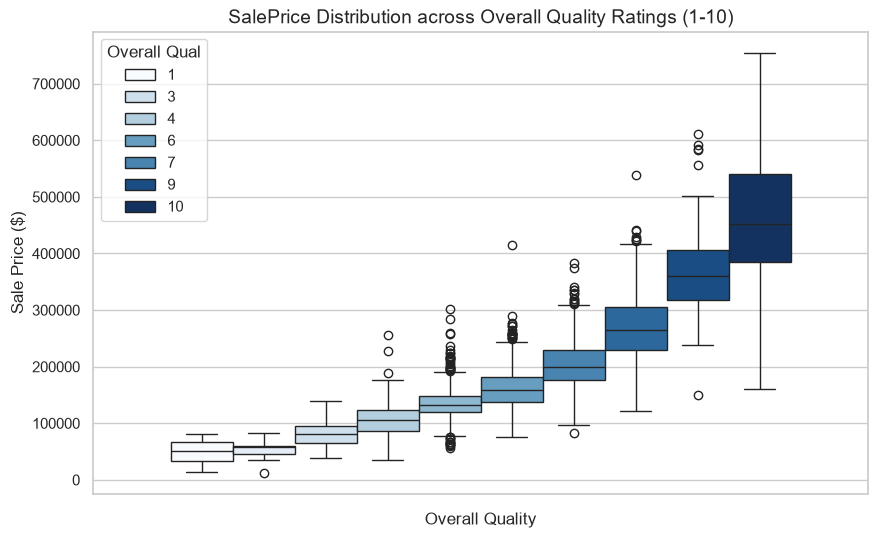

In [15]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, hue='Overall Qual', y='SalePrice', palette='Blues')
plt.title('SalePrice Distribution across Overall Quality Ratings (1-10)', fontsize=14)
plt.xlabel('Overall Quality')
plt.ylabel('Sale Price ($)')
plt.show()